# Market Risk Lab: VaR, CVaR and backtesting

## Problem
How much can an equal-weight SPY/QQQ/TLT/GLD portfolio lose in one day at the 99% level, and which way of measuring it can be trusted? A risk number is only useful if it passes a backtest.

## Data
Adjusted daily closes for SPY, QQQ, TLT and GLD from Yahoo Finance (yfinance), last 8 years; log returns of an equal-weight portfolio.

## Method
$\text{VaR}_\alpha=-q_\alpha(R)$ and $\text{CVaR}_\alpha=-\mathbb{E}[R\mid R\le -\text{VaR}_\alpha]$. Three estimators: historical quantile, parametric normal, and EWMA volatility ($\lambda=0.94$) with Student-t shocks by Monte Carlo. Rolling 500-day window backtest; Kupiec test for coverage and Christoffersen test for independence of breaches.

In [1]:
import warnings, sys; warnings.filterwarnings('ignore'); sys.path[:0] = ['..', '.']
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import risk_lab as R
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
rets = R.load_returns(['SPY','QQQ','TLT','GLD']); pr = rets.mean(axis=1)
print(pr.index.min().date(), 'to', pr.index.max().date(), '|', len(pr), 'days')
print('Annualised vol:', round(pr.std()*np.sqrt(252),3), '| worst day:', round(pr.min(),4), '| skew', round(pr.skew(),2), '| excess kurtosis', round(pr.kurt(),2))

2018-11-20 to 2026-11-19 | 2010 days
Annualised vol: 0.128 | worst day: -0.0578 | skew -0.23 | excess kurtosis 6.46


{'historical VaR': '2.25%', 'normal VaR': '1.83%', 'EWMA-t MC VaR': '2.55%', 'historical CVaR': '3.06%'}


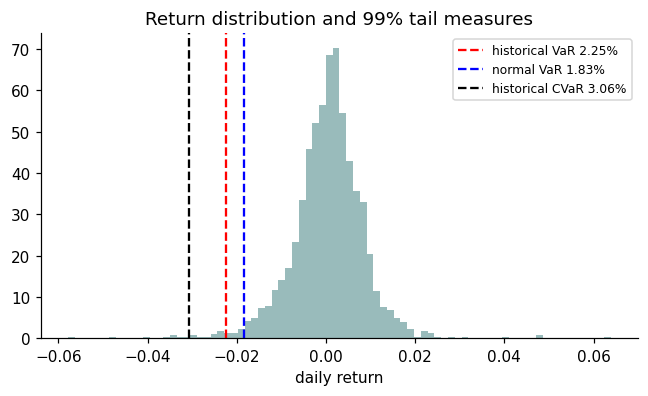

In [2]:
a = 0.01
row = {'historical VaR': R.var_hist(pr,a), 'normal VaR': R.var_norm(pr,a), 'EWMA-t MC VaR': R.var_ewma_mc(pr,a), 'historical CVaR': R.cvar_hist(pr,a)}
print({k: f'{v:.2%}' for k,v in row.items()})
fig, ax = plt.subplots(figsize=(7,3.6)); ax.hist(pr, bins=80, color='#9bb', density=True)
for k,c in [('historical VaR','r'),('normal VaR','b'),('historical CVaR','k')]: ax.axvline(-row[k], c=c, ls='--', label=f'{k} {row[k]:.2%}')
ax.set_xlabel('daily return'); ax.legend(fontsize=8); ax.set_title('Return distribution and 99% tail measures'); plt.show()

            breach rate  expected  Kupiec p  Christoffersen p  breaches  \
historical        0.011      0.01     0.818             0.160      16.0   
parametric        0.017      0.01     0.011             0.468      26.0   
ewma_t            0.016      0.01     0.034             0.395      24.0   

              days  
historical  1510.0  
parametric  1510.0  
ewma_t      1510.0  


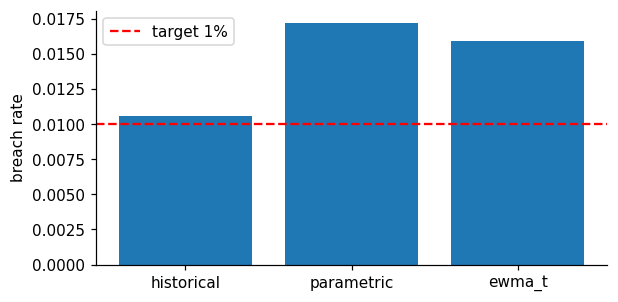

In [3]:
bt = R.backtest(pr, a)
res = pd.DataFrame({k: {'breach rate': b.mean(), 'expected': a, 'Kupiec p': R.kupiec(b,a), 'Christoffersen p': R.christoffersen(b), 'breaches': int(b.sum()), 'days': len(b)} for k,b in bt.items()}).T
print(res.round(3))
fig, ax = plt.subplots(figsize=(6,3)); ax.bar(res.index, res['breach rate']); ax.axhline(a, c='r', ls='--', label='target 1%'); ax.set_ylabel('breach rate'); ax.legend(); plt.show()

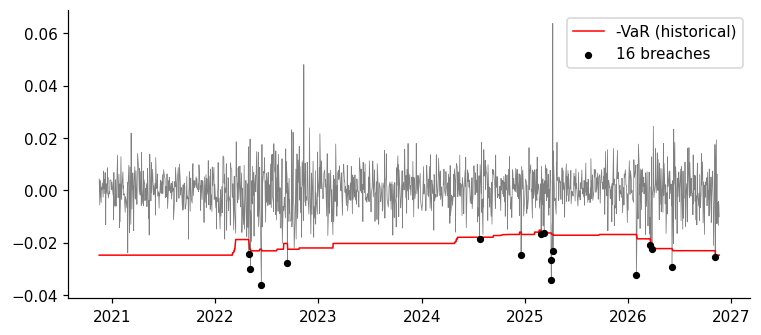

Breaches by year: {2022: 4, 2024: 2, 2025: 5, 2026: 5}


In [4]:
# Where do breaches cluster? Plot portfolio returns, with historical-VaR breaches marked
win=500; hv = pd.Series([R.var_hist(pr.iloc[i-win:i], a) for i in range(win, len(pr))], index=pr.index[win:])
rr = pr.iloc[win:]
fig, ax = plt.subplots(figsize=(8,3.4)); ax.plot(rr.index, rr, lw=.5, c='gray'); ax.plot(hv.index, -hv, c='r', lw=1, label='-VaR (historical)')
br = rr[rr < -hv]; ax.scatter(br.index, br, c='k', s=14, zorder=3, label=f'{len(br)} breaches'); ax.legend(); plt.show()
print('Breaches by year:', br.groupby(br.index.year).size().to_dict())

## Results
See the outputs above: the three 99% VaR estimates and the CVaR, the backtest table with Kupiec and Christoffersen p-values, and the timing of breaches.

## Conclusions
1. **The portfolio has fat tails, so the normal model is too optimistic.** Excess kurtosis is 6.46 and the 99% VaR is 2.25% by the historical method against 1.83% by the normal model; the historical CVaR is 3.06%, meaning that on the worst 1% of days the average loss is about 0.8 points beyond the VaR.
2. **Only the historical method passed the backtest.** Over 1,510 out-of-sample days the historical VaR was breached 16 times (1.1%, target 1%; Kupiec p = 0.82), whereas the normal model was breached 26 times (1.7%, p = 0.011) and the EWMA Student-t model 24 times (1.6%, p = 0.034). Both of the latter are rejected at the 5% level, i.e. they under-estimate risk.
3. **The EWMA model is not better here.** Its higher VaR (2.55%) is not enough because it breaches more often than expected, which suggests the volatility scaling (lambda = 0.94) and the t shocks (5 degrees of freedom) do not describe this portfolio's tails; a tuned GARCH model or a longer window would be the next test.
4. **Breaches cluster in stress years.** All 16 historical breaches occurred in 2022 (4), 2024 (2), 2025 (5) and 2026 (5), none in the calm years between, and the Christoffersen independence test does not reject (p = 0.16), so the evidence of clustering is not statistically significant.
5. **Limits.** Only 16 to 26 breaches per method means the tests have limited power; the portfolio is linear with fixed equal weights; results depend on the 500-day window and on 2018 to 2026 market conditions.

**Takeaway for the interview:** a risk model is a hypothesis; report it with a backtest. Here the simplest non-parametric estimator was the only one not rejected, and the "more sophisticated" ones were worse.